<a href="https://colab.research.google.com/github/SabaFeizi/Machine-Learning-Fall2026/blob/main/Logistic_Regression_Heart_Disease_(Short).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl">

# 🫀 آیا این بیمار بیماری قلبی دارد؟
### حل یک مسئلهٔ واقعی دسته‌بندی با رگرسیون لجستیک — از دادهٔ خام تا «احتمال» و تصمیم

پروندهٔ **۹۲۰ بیمار** از چهار مرکز درمانی (کلیولند و لانگ‌بیچ در آمریکا، بوداپست در مجارستان و زوریخ و بازل در سوئیس) به دستمان رسیده است. همه با درد قفسهٔ سینه مراجعه کرده‌اند، چند آزمایش ساده (سن، فشار خون، کلسترول، نوار قلب، تست ورزش و ...) داده‌اند و بعد با **آنژیوگرافی** معلوم شده که رگ‌های قلبشان تنگ شده است یا نه.

پزشکان می‌پرسند:

> «برای بیمار جدید فقط نگو بیمار است یا سالم؛ بگو **چقدر احتمال دارد** که بیمار باشد.»

پرسپترون جلسهٔ قبل فقط برچسب سخت می‌داد. ولی بیماری که مدل با **۹۹٪** اطمینان بیمار می‌داند با بیماری که فقط **۵۱٪** است فرق بزرگی دارد (اسلاید ۷). رگرسیون لجستیک دقیقاً همین **احتمال** را می‌دهد.

| قدم | چه کار می‌کنیم؟ | ابزار اصلی |
|---|---|---|
| ۱–۲ | با داده آشنا می‌شویم و دادهٔ گمشده (آشکار و پنهان!) را پیدا می‌کنیم | `pandas`, `seaborn` |
| ۳–۴ | تقسیم داده، پر کردن جاهای خالی، one-hot و scaling | `SimpleImputer`, `OneHotEncoder`, `StandardScaler` |
| ۵–۶ | اولین مدل لجستیک، خروجی‌هایش و مرزهای تصمیم خطی و غیرخطی | `LogisticRegression`, `PolynomialFeatures` |
| ۷–۹ | cross-entropy، MLE در برابر MAP (L2 و L1) و گرادیان کاهشی | `log_loss`, `SGDClassifier` |
| ۱۰ | accuracy، precision، recall، F1، ROC-AUC و انتخاب آستانه | `sklearn.metrics` |
| ۱۱ | همه‌چیز در یک Pipeline با GridSearchCV | `Pipeline`, `GridSearchCV` |
| ۱۲ | رگرسیون Softmax روی پنگوئن‌ها 🐧 | `LogisticRegression` |
| ۱۳ | ارزیابی نهایی روی test | همه‌چیز! |

💡 **قرارداد این نوت‌بوک:** هیچ مدلی را از صفر نمی‌نویسیم. همه را با `scikit-learn` می‌سازیم و تمرکزمان روی **درست به کار بردن** ابزارها و **درست خواندن** خروجی‌هایشان است. فقط گاهی با یکی دو خط `numpy` نشان می‌دهیم که کتابخانه همان فرمول اسلایدها را حساب می‌کند.

</div>

<div dir="rtl">

## ۰. آماده‌سازی

</div>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")          # a clean look for all plots
plt.rcParams["figure.figsize"] = (7, 4.5)

<div dir="rtl">

## ۱. آشنایی با داده

دیتاست **Heart Disease** از مخزن دادهٔ UCI (سال ۱۹۸۸):

</div>

In [ ]:
df = pd.read_csv("/content/heart_disease_uci.csv")
print(df.shape)
df.head()

(920, 16)


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


<div dir="rtl">

| ستون | معنی |
|---|---|
| `age`، `sex` | سن و جنسیت |
| `dataset` | مرکز درمانی‌ای که پرونده از آن آمده است |
| `cp` | نوع درد قفسهٔ سینه: `typical angina`، `atypical angina`، `non-anginal` یا `asymptomatic` (بدون علامت) |
| `trestbps` | فشار خون در حالت استراحت (mmHg) |
| `chol` | کلسترول خون (mg/dL) |
| `fbs` | آیا قند خون ناشتا بیشتر از ۱۲۰ mg/dL است؟ |
| `restecg` | نتیجهٔ نوار قلب در حالت استراحت |
| `thalch` | بیشترین ضربان قلب در تست ورزش (ضربه در دقیقه) |
| `exang` | آیا ورزش باعث درد قفسهٔ سینه شد؟ |
| `oldpeak` | افت «قطعهٔ ST» نوار قلب هنگام ورزش (mm)؛ نشانهٔ کم‌خونی عضلهٔ قلب |
| `slope` | شیب قطعهٔ ST در اوج ورزش |
| `ca`، `thal` | نتیجهٔ فلوروسکوپی و تست تالیوم |
| **`num`** | **شدت تنگی عروق: ۰ = سالم، ۱ تا ۴ = بیمار** |

</div>

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB


<div dir="rtl">

- چند ستون کمتر از ۹۲۰ مقدار دارند: **دادهٔ گمشده** داریم.
- چند ستون از نوع `object` (متن) هستند، مثل `cp`؛ باید عددی شوند (بخش ۴.۲).

**هدف:** ستون `num` پنج مقدار دارد. هر عدد بزرگ‌تر از صفر را «بیمار» (۱) و صفر را «سالم» (۰) می‌گیریم:

</div>

In [ ]:
df["target"] = (df["num"] > 0).astype(int)      # 1 = heart disease, 0 = healthy

print(df["target"].value_counts())
print("Share of patients with heart disease:", round(df["target"].mean(), 3))

target
1    509
0    411
Name: count, dtype: int64
Share of patients with heart disease: 0.553


<div dir="rtl">

حدود ۵۵٪ بیمار و ۴۵٪ سالم: دو کلاس **تقریباً متوازن‌اند**.

⚠️ ستون `dataset` را کنار می‌گذاریم: در سوئیس ۱۱۵ نفر از ۱۲۳ نفر بیمارند و مدل ممکن است یاد بگیرد «سوئیسی = بیمار». اسم بیمارستان **ویژگی بیمار** نیست. (در تمرین‌ها به آن برمی‌گردیم.)

</div>

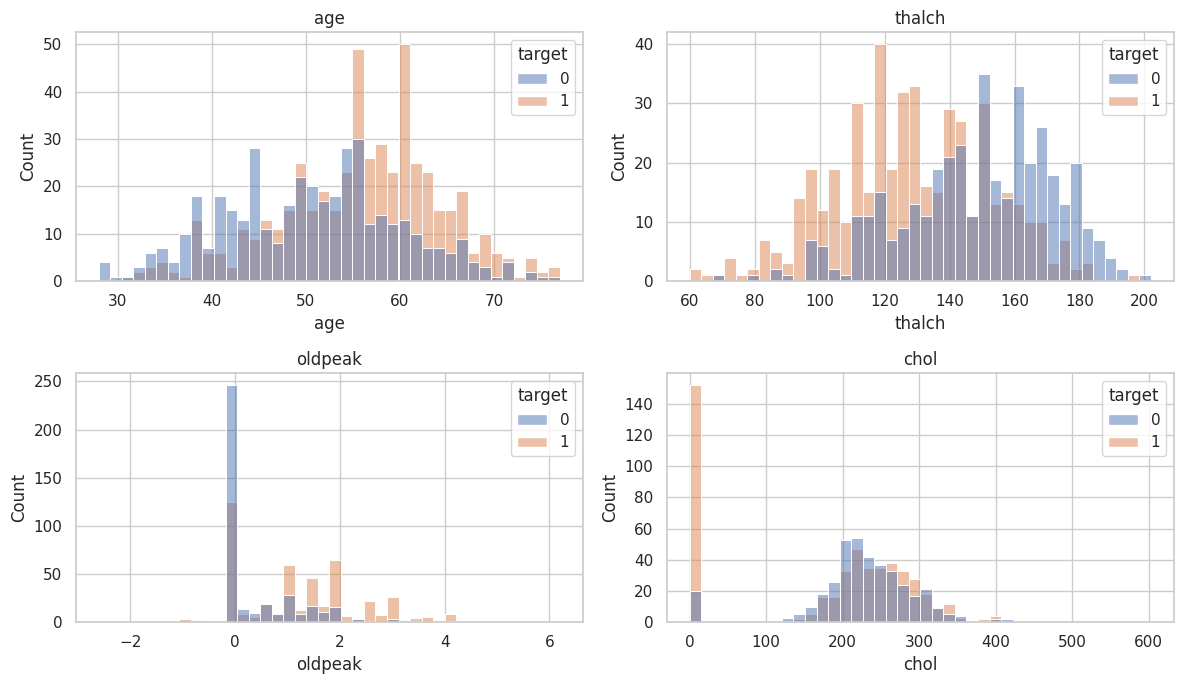

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for ax, column in zip(axes.ravel(), ["age", "thalch", "oldpeak", "chol"]):
    sns.histplot(data=df, x=column, hue="target", bins=40, ax=ax)
    ax.set_title(column)

plt.tight_layout()
plt.show()

<div dir="rtl">

- بیماران (نارنجی) به ضربان **پایین‌تری** می‌رسند (`thalch`)، افت ST **بیشتری** دارند (`oldpeak`) و کمی مسن‌ترند.
- دو گروه **روی هم افتاده‌اند**؛ هیچ ویژگی تنهایی همه را جدا نمی‌کند.
- در `chol` یک ستون عجیب روی **صفر** هست! کلسترول صفر غیرممکن است.

</div>

<div dir="rtl">

## ۲. 🔍 کارآگاه داده

### ۲.۱ دادهٔ گمشدهٔ آشکار

</div>

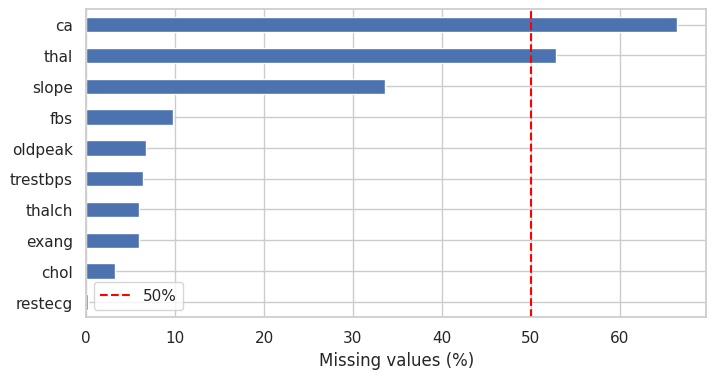

In [ ]:
missing_percent = df.isna().mean().mul(100).sort_values()
missing_percent = missing_percent[missing_percent > 0]

missing_percent.plot.barh(figsize=(8, 4))
plt.axvline(50, color="red", linestyle="--", label="50%")
plt.xlabel("Missing values (%)")
plt.legend()
plt.show()

<div dir="rtl">

- **`ca`** و **`thal`** بیش از نصفشان خالی است؛ اگر پرشان کنیم بیشترشان **ساختگی** می‌شوند. حذفشان می‌کنیم.
- **`slope`** حدود یک‌سوم خالی است؛ نگهش می‌داریم و پرش می‌کنیم. بقیه فقط چند درصد خالی‌اند.

### ۲.۲ دادهٔ گمشده در لباس مبدل (دوباره!)

مثل دیتاست دیابت، این‌جا هم «صفر» گاهی یعنی «اندازه‌گیری نشده»:

</div>

In [ ]:
print("chol == 0:    ", (df["chol"] == 0).sum())
print("trestbps == 0:", (df["trestbps"] == 0).sum())
print()
print((df["chol"] == 0).groupby(df["dataset"]).sum())

chol == 0:     172
trestbps == 0: 1

dataset
Cleveland          0
Hungary            0
Switzerland      123
VA Long Beach     49
Name: chol, dtype: int64


<div dir="rtl">

**همهٔ** بیماران سوئیسی کلسترول صفر دارند: آن مرکز اصلاً کلسترول را ثبت نکرده است.

همهٔ پاک‌سازی را در یک سلول انجام می‌دهیم. این‌ها **قاعده‌های ثابت**‌اند و چیزی از داده یاد نمی‌گیرند، پس قبل از تقسیم داده مشکلی ندارند:

۱. حذف ستون‌های `id`، `dataset`، `ca`، `thal` و `num`.

۲. صفرهای غیرممکن ← `NaN`.

۳. حذف ردیف‌های تکراری.

۴. تبدیل سه ستون دوحالته (`sex`، `fbs`، `exang`) به ۱ و ۰ (جاهای خالی خالی می‌مانند).

</div>

In [ ]:
data = df.drop(columns=["id", "dataset", "ca", "thal", "num"])

data["chol"] = data["chol"].replace(0, np.nan)
data["trestbps"] = data["trestbps"].replace(0, np.nan)

print("Duplicated rows:", data.duplicated().sum())
data = data.drop_duplicates()

data["sex"] = data["sex"].map({"Male": 1, "Female": 0})
data["fbs"] = data["fbs"].map({True: 1, False: 0})
data["exang"] = data["exang"].map({True: 1, False: 0})

print(data.shape)
data.isna().sum()

Duplicated rows: 2
(918, 12)


,0
age,0
sex,0
cp,0
trestbps,60
chol,201
fbs,90
restecg,2
thalch,55
exang,55
oldpeak,62


<div dir="rtl">

## ۳. تقسیم داده: Train / Validation / Test

مثل همیشه ۶۰٪ / ۲۰٪ / ۲۰٪ با `stratify=y`. ستون‌ها را هم دو دسته می‌کنیم، چون پیش‌پردازششان فرق دارد: **عددی** (شامل ستون‌های ۰/۱) و **متنی** (`cp`، `restecg`، `slope`).

💡 برخلاف پرسپترون (۱+ و ۱-)، در رگرسیون لجستیک برچسب‌ها **۱ و ۰** هستند؛ چون مدل احتمال <span dir="ltr">$P(y = 1 \mid \mathbf{x})$</span> را پیش‌بینی می‌کند.

</div>

In [ ]:
from sklearn.model_selection import train_test_split

numeric_cols = ["age", "sex", "trestbps", "chol", "fbs", "thalch", "exang", "oldpeak"]
categorical_cols = ["cp", "restecg", "slope"]

X = data[numeric_cols + categorical_cols]
y = data["target"].to_numpy()

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)

print("Train:     ", X_train.shape, " share sick:", round(y_train.mean(), 3))
print("Validation:", X_val.shape, " share sick:", round(y_val.mean(), 3))
print("Test:      ", X_test.shape, " share sick:", round(y_test.mean(), 3))

Train:      (550, 11)  share sick: 0.553
Validation: (184, 11)  share sick: 0.554
Test:       (184, 11)  share sick: 0.554


<div dir="rtl">

## ۴. پیش‌پردازش: Imputation، One-Hot و Scaling

قانون طلایی: هر ابزاری که چیزی از داده **یاد می‌گیرد**، **`fit` فقط روی train** و **`transform` روی هر سه بخش**.

### ۴.۱ پر کردن جاهای خالی با `SimpleImputer`

- ستون‌های عددی ← **میانه** (`median`). برای ستون‌های ۰/۱، میانه همان مقدار پرتکرارتر است.
- ستون‌های متنی میانه ندارند ← **پرتکرارترین مقدار** (`most_frequent`).

</div>

In [ ]:
from sklearn.impute import SimpleImputer

num_imputer = SimpleImputer(strategy="median")
cat_imputer = SimpleImputer(strategy="most_frequent")

num_imputer.fit(X_train[numeric_cols])
cat_imputer.fit(X_train[categorical_cols])

print(pd.Series(num_imputer.statistics_, index=numeric_cols))
print(pd.Series(cat_imputer.statistics_, index=categorical_cols))

age          54.0
sex           1.0
trestbps    130.0
chol        243.0
fbs           0.0
thalch      140.0
exang         0.0
oldpeak       0.6
dtype: float64
cp         asymptomatic
restecg          normal
slope              flat
dtype: object


<div dir="rtl">

برای این‌که کد یکسان را سه بار ننویسیم، یک تابع کوچک می‌سازیم:

</div>

In [ ]:
def impute(X):
    X = X.copy()
    X[numeric_cols] = num_imputer.transform(X[numeric_cols])
    X[categorical_cols] = cat_imputer.transform(X[categorical_cols])
    return X


X_train_imp = impute(X_train)
X_val_imp = impute(X_val)
X_test_imp = impute(X_test)

print("Missing values left:", X_train_imp.isna().sum().sum(), X_val_imp.isna().sum().sum(), X_test_imp.isna().sum().sum())

Missing values left: 0 0 0


<div dir="rtl">

### ۴.۲ ستون‌های متنی: One-Hot Encoding

نمی‌شود «`non-anginal`» را در یک وزن ضرب کرد! اگر هم به حالت‌ها عدد ۱، ۲، ۳، ۴ بدهیم، یک **ترتیب ساختگی** ساخته‌ایم. راه درست: برای هر حالت یک ستون ۰/۱ جدا (همان «۱-از-K» اسلاید ۴۹). `OneHotEncoder` حالت‌ها را از train یاد می‌گیرد:

</div>

In [ ]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False)
encoder.fit(X_train_imp[categorical_cols])


def encode(X):
    onehot = pd.DataFrame(encoder.transform(X[categorical_cols]),
                          columns=encoder.get_feature_names_out(), index=X.index)
    return pd.concat([X[numeric_cols], onehot], axis=1)


X_train_enc = encode(X_train_imp)
X_val_enc = encode(X_val_imp)
X_test_enc = encode(X_test_imp)

print(X_train_enc.shape)
X_train_enc.head(3)

(550, 18)


,age,sex,trestbps,chol,fbs,thalch,exang,oldpeak,cp_asymptomatic,cp_atypical angina,cp_non-anginal,cp_typical angina,restecg_lv hypertrophy,restecg_normal,restecg_st-t abnormality,slope_downsloping,slope_flat,slope_upsloping
767,51.0,1.0,128.0,243.0,0.0,107.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
134,43.0,0.0,122.0,213.0,0.0,165.0,0.0,0.2,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
474,57.0,0.0,130.0,308.0,0.0,98.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0


<div dir="rtl">

از ۱۱ ستون به **۱۸ ستون** عددی رسیدیم. در هر گروه one-hot (مثلاً چهار ستون `cp_...`) دقیقاً یکی ۱ است.

### ۴.۳ هم‌مقیاس کردن با `StandardScaler`

کلسترول در حد صدها، `oldpeak` در حد چند واحد و ستون‌های one-hot فقط ۰ و ۱ هستند. توصیهٔ اول اسلاید ۴۰ همین است: **ویژگی‌ها را استاندارد کن**؛ وگرنه گرادیان کاهشی کند یا واگرا می‌شود و منظم‌سازی (بخش ۸) با همهٔ وزن‌ها منصفانه رفتار نمی‌کند.

</div>

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train_enc)

X_train_scaled = pd.DataFrame(scaler.transform(X_train_enc), columns=X_train_enc.columns, index=X_train_enc.index)
X_val_scaled = pd.DataFrame(scaler.transform(X_val_enc), columns=X_train_enc.columns, index=X_val_enc.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_enc), columns=X_train_enc.columns, index=X_test_enc.index)

X_train_scaled.describe().loc[["mean", "std"]].round(2)

,age,sex,trestbps,chol,fbs,thalch,exang,oldpeak,cp_asymptomatic,cp_atypical angina,cp_non-anginal,cp_typical angina,restecg_lv hypertrophy,restecg_normal,restecg_st-t abnormality,slope_downsloping,slope_flat,slope_upsloping
mean,0.0,-0.0,0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


<div dir="rtl">

## ۵. اولین مدل لجستیک: دو ویژگی

رگرسیون لجستیک همان امتیاز خطی پرسپترون را حساب می‌کند، ولی به‌جای تابع پله آن را از **سیگموید** رد می‌کند (اسلایدهای ۱۱ تا ۱۳):

</div>

$$\sigma(z) = \frac{1}{1 + e^{-z}} \qquad\qquad P(y = 1 \mid \mathbf{x}) = \sigma(\mathbf{w}^T\mathbf{x}) = \sigma(w_0 + w_1 x_1 + \dots + w_d x_d)$$

<div dir="rtl">

خروجی سیگموید همیشه بین ۰ و ۱ است (پس **احتمال** است) و همه‌جا مشتق دارد (پس با **گرادیان کاهشی** آموزش می‌بیند). لجستیک یک «پرسپترون نرم» است.

### ۵.۱ ساختن مدل

برای این‌که بتوانیم رسم کنیم، با دو ویژگی شروع می‌کنیم: **بیشترین ضربان قلب** (`thalch`) و **افت ST** (`oldpeak`).

</div>

In [ ]:
from sklearn.linear_model import LogisticRegression

two_features = ["thalch", "oldpeak"]

X_train_2 = X_train_scaled[two_features]
X_val_2 = X_val_scaled[two_features]
X_test_2 = X_test_scaled[two_features]

log_reg_2 = LogisticRegression()
log_reg_2.fit(X_train_2, y_train)

print("w0 (intercept_):", log_reg_2.intercept_.round(3))
print("w1, w2 (coef_): ", log_reg_2.coef_.round(3))

w0 (intercept_): [0.315]
w1, w2 (coef_):  [[-0.879  0.783]]


<div dir="rtl">

یعنی (با ویژگی‌های استانداردشده):

</div>

$$P(\text{disease} \mid \mathbf{x}) = \sigma\big(0.31 - 0.88 \cdot \text{thalch} + 0.78 \cdot \text{oldpeak}\big)$$

<div dir="rtl">

ضربان بالاتر احتمال بیماری را **کم** می‌کند (وزن منفی) و افت ST بیشتر آن را **زیاد** می‌کند (وزن مثبت)؛ همان چیزی که در نمودارها دیدیم.

### ۵.۲ سه خروجی مدل و حساب دستی

| متد | چه چیزی برمی‌گرداند؟ |
|---|---|
| `decision_function(X)` | امتیاز خطی <span dir="ltr">$z = \mathbf{w}^T\mathbf{x}$</span> |
| `predict_proba(X)` | <span dir="ltr">$[1 - \sigma(z),\ \sigma(z)]$</span>، یک ستون برای هر کلاس (جمعشان ۱) |
| `predict(X)` | ۱ اگر <span dir="ltr">$\sigma(z) \ge 0.5$</span>، وگرنه ۰ |

</div>

In [ ]:
z_by_hand = log_reg_2.intercept_[0] + X_val_2.to_numpy() @ log_reg_2.coef_[0]
p_by_hand = 1 / (1 + np.exp(-z_by_hand))

pd.DataFrame({
    "z by hand": z_by_hand,
    "decision_function": log_reg_2.decision_function(X_val_2),
    "sigmoid(z) by hand": p_by_hand,
    "predict_proba[:, 0]": log_reg_2.predict_proba(X_val_2)[:, 0],
    "predict_proba[:, 1]": log_reg_2.predict_proba(X_val_2)[:, 1],
    "predict": log_reg_2.predict(X_val_2),
}).head().round(3)

,z by hand,decision_function,sigmoid(z) by hand,"predict_proba[:, 0]","predict_proba[:, 1]",predict
0,-0.963,-0.963,0.276,0.724,0.276,0
1,0.908,0.908,0.713,0.287,0.713,1
2,1.295,1.295,0.785,0.215,0.785,1
3,2.060,2.060,0.887,0.113,0.887,1
4,1.028,1.028,0.736,0.264,0.736,1


<div dir="rtl">

حساب دستی دقیقاً با کتابخانه یکی است. ✅

### ۵.۳ لجستیک در برابر پرسپترون: برچسب یا اطمینان؟

یک `Perceptron` هم روی همین دو ویژگی آموزش می‌دهیم و دو بیمار validation را کنار هم می‌گذاریم: کسی که لجستیک **مطمئن‌ترین** پیش‌بینی را برایش دارد و کسی که احتمالش **نزدیک‌ترین** به ۰٫۵ است:

</div>

In [ ]:
from sklearn.linear_model import Perceptron

perceptron_2 = Perceptron(random_state=0)
perceptron_2.fit(X_train_2, y_train)

p_val_2 = log_reg_2.predict_proba(X_val_2)[:, 1]
sure = np.argmax(p_val_2)                     # the most confident prediction
unsure = np.argmin(np.abs(p_val_2 - 0.5))     # the prediction closest to a coin flip

two_patients = X_val.iloc[[sure, unsure]][two_features].copy()
two_patients["perceptron says"] = perceptron_2.predict(X_val_2.iloc[[sure, unsure]])
two_patients["logistic says"] = log_reg_2.predict(X_val_2.iloc[[sure, unsure]])
two_patients["P(disease)"] = p_val_2[[sure, unsure]].round(3)
two_patients["truth"] = y_val[[sure, unsure]]
two_patients

,thalch,oldpeak,perceptron says,logistic says,P(disease),truth
123,111.0,5.6,1,1,0.992,1
621,128.0,0.0,0,0,0.497,1


<div dir="rtl">

هر دو مدل فقط برچسب می‌دهند، ولی لجستیک **بیشتر** می‌گوید: بیمار اول تقریباً **قطعاً** بیمار است، ولی دربارهٔ دومی مدل عملاً **سکه می‌اندازد**. اتفاقاً بیمار دوم واقعاً بیمار است و هر دو مدل او را «سالم» دانسته‌اند! پرسپترون نمی‌توانست بگوید این پیش‌بینی چقدر لرزان است؛ لجستیک می‌گوید و پزشک می‌تواند آزمایش بیشتری بخواهد.

</div>

<div dir="rtl">

## ۶. مرز تصمیم

### ۶.۱ مرز لجستیک یک خط است

مرز تصمیم جایی است که <span dir="ltr">$P(y=1 \mid \mathbf{x}) = 0.5$</span>. چون <span dir="ltr">$\sigma(0) = 0.5$</span>:

</div>

$$\sigma(\mathbf{w}^T\mathbf{x}) = 0.5 \iff \mathbf{w}^T\mathbf{x} = 0 \qquad\qquad \sigma(\mathbf{w}^T\mathbf{x}) = c \iff \mathbf{w}^T\mathbf{x} = \log\frac{c}{1-c}$$

<div dir="rtl">

پس مرز یک **خط** (ابرصفحه) است و هر «خط هم‌احتمال» دیگر هم خطی **موازی** آن است (اسلاید ۱۹). یک تابع کمکی برای رسم می‌نویسیم که در ادامه چند بار از آن استفاده می‌کنیم:

</div>

In [ ]:
def plot_probability_map(model, X, y, ax, title=""):
    # a fine grid of points that covers the data
    x1_values = np.linspace(X.iloc[:, 0].min() - 0.5, X.iloc[:, 0].max() + 0.5, 300)
    x2_values = np.linspace(X.iloc[:, 1].min() - 0.5, X.iloc[:, 1].max() + 0.5, 300)
    x1_grid, x2_grid = np.meshgrid(x1_values, x2_values)
    grid = pd.DataFrame({X.columns[0]: x1_grid.ravel(), X.columns[1]: x2_grid.ravel()})

    # the probability of class 1 at every grid point
    proba = model.predict_proba(grid)[:, 1].reshape(x1_grid.shape)

    filled = ax.contourf(x1_grid, x2_grid, proba, levels=np.linspace(0, 1, 11), cmap="coolwarm", alpha=0.5)
    lines = ax.contour(x1_grid, x2_grid, proba, levels=[0.1, 0.3, 0.7, 0.9], colors="gray", linewidths=0.8)
    ax.clabel(lines, fmt="%.1f")
    ax.contour(x1_grid, x2_grid, proba, levels=[0.5], colors="black", linewidths=2.5)   # the decision boundary
    ax.scatter(X.iloc[:, 0], X.iloc[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=20)
    ax.set_xlabel(X.columns[0])
    ax.set_ylabel(X.columns[1])
    ax.set_title(title)
    return filled

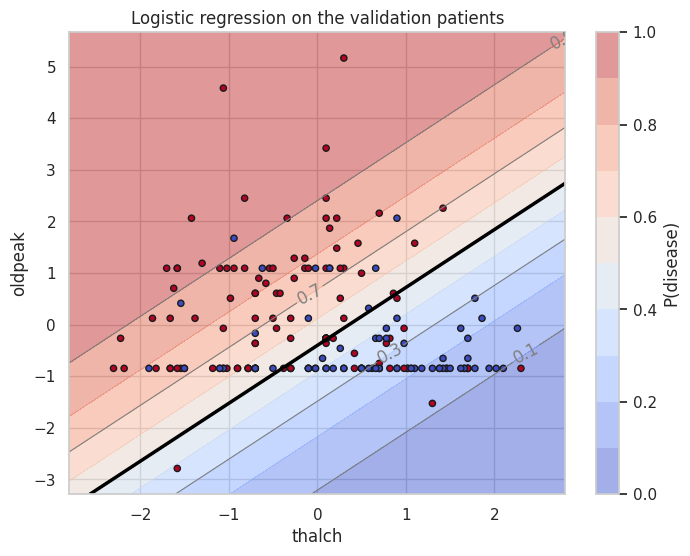

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
filled = plot_probability_map(log_reg_2, X_val_2, y_val, ax, "Logistic regression on the validation patients")
plt.colorbar(filled, label="P(disease)")
plt.show()

<div dir="rtl">

- **خط سیاه** مرز تصمیم است. بالا و چپ آن (ضربان کم، افت ST زیاد) قرمز است: بیمار.
- خطوط خاکستری (۰٫۱، ۰٫۳، ۰٫۷، ۰٫۹) همه **موازی** مرزند؛ هرچه دورتر، مدل مطمئن‌تر.
- نقطه‌های زیادی طرف اشتباه‌اند: دو کلاس با این دو ویژگی **روی هم افتاده‌اند**.

### ۶.۲ مرز غیرخطی با نگاشت ویژگی (Feature Map)

اسلایدهای ۲۲ و ۲۳: اگر مرز واقعی خط نباشد، **ویژگی‌های جدید بساز**، مثلاً <span dir="ltr">$\phi(\mathbf{x}) = (x_1^2, x_2^2)$</span>، و همان لجستیک خطی را روی آن‌ها اجرا کن. با `make_circles` داده‌ای می‌سازیم که مرزش یک **دایره** است و سه مدل را مقایسه می‌کنیم:

۱. لجستیک روی <span dir="ltr">$(x_1, x_2)$</span>.

۲. لجستیک روی <span dir="ltr">$(x_1^2, x_2^2)$</span>.

۳. یک Pipeline با `PolynomialFeatures` که همهٔ جمله‌های درجهٔ ۲ را می‌سازد و بعد لجستیک را فیت می‌کند.

</div>

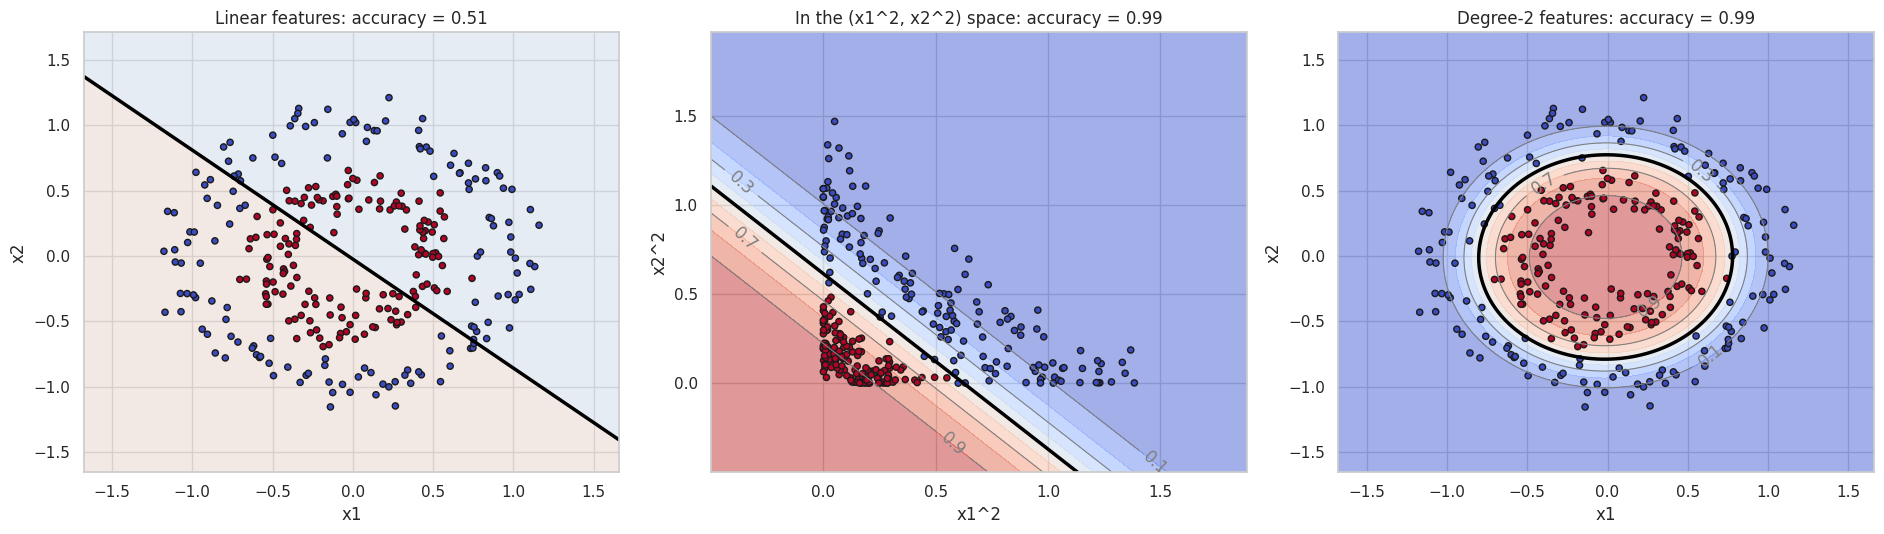

In [ ]:
from sklearn.datasets import make_circles
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

X_circles, y_circles = make_circles(n_samples=300, noise=0.1, factor=0.5, random_state=0)
X_circles = pd.DataFrame(X_circles, columns=["x1", "x2"])

X_circles_squared = X_circles ** 2                  # the feature map phi(x) = (x1^2, x2^2)
X_circles_squared.columns = ["x1^2", "x2^2"]

linear_circles = LogisticRegression().fit(X_circles, y_circles)
squared_circles = LogisticRegression().fit(X_circles_squared, y_circles)
poly_circles = make_pipeline(PolynomialFeatures(degree=2), LogisticRegression()).fit(X_circles, y_circles)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
plot_probability_map(linear_circles, X_circles, y_circles, axes[0],
                     f"Linear features: accuracy = {linear_circles.score(X_circles, y_circles):.2f}")
plot_probability_map(squared_circles, X_circles_squared, y_circles, axes[1],
                     f"In the (x1^2, x2^2) space: accuracy = {squared_circles.score(X_circles_squared, y_circles):.2f}")
plot_probability_map(poly_circles, X_circles, y_circles, axes[2],
                     f"Degree-2 features: accuracy = {poly_circles.score(X_circles, y_circles):.2f}")
plt.tight_layout()
plt.show()

<div dir="rtl">

- **چپ:** هیچ خطی دایره را جدا نمی‌کند؛ دقت حدود ۵۰٪، یعنی سکه انداختن!
- **وسط:** در فضای <span dir="ltr">$(x_1^2, x_2^2)$</span> دایره یک **خط راست** شده است.
- **راست:** همان ایده در فضای اصلی: مرز یک **دایره** است.

💡 الگوریتم عوض نشد؛ مدل نسبت به <span dir="ltr">$\mathbf{w}$</span> هنوز **خطی** است. فقط وقتی مرز را در فضای اصلی رسم می‌کنیم خمیده دیده می‌شود.

</div>

<div dir="rtl">

## ۷. تابع هزینه: Cross-Entropy

### ۷.۱ از درست‌نمایی تا cross-entropy

بیشینه کردن درست‌نمایی (MLE) همان کمینه کردن **منفی لگاریتم درست‌نمایی** است، یعنی **cross-entropy** یا **log loss** (اسلایدهای ۲۵ تا ۲۷):

</div>

$$J(\mathbf{w}) = -\frac{1}{n}\sum_{i=1}^{n} \Big[\,y^{(i)} \log p^{(i)} + (1 - y^{(i)})\log(1 - p^{(i)})\,\Big] \qquad\qquad p^{(i)} = \sigma(\mathbf{w}^T\mathbf{x}^{(i)})$$

<div dir="rtl">

اگر بیمار واقعاً بیمار باشد و مدل بگوید <span dir="ltr">$p = 0.99$</span>، جریمه تقریباً صفر است؛ ولی اگر **با اطمینان اشتباه کند** (<span dir="ltr">$p = 0.01$</span>)، جریمه به سمت بی‌نهایت می‌رود. `sklearn.metrics.log_loss` همین را حساب می‌کند:

</div>

In [ ]:
from sklearn.metrics import log_loss

p_train_2 = log_reg_2.predict_proba(X_train_2)[:, 1]
loss_by_hand = -np.mean(y_train * np.log(p_train_2) + (1 - y_train) * np.log(1 - p_train_2))

print("Train log loss (by hand):", round(loss_by_hand, 4))
print("Train log loss (sklearn):", round(log_loss(y_train, p_train_2), 4))
print("Validation log loss:     ", round(log_loss(y_val, p_val_2), 4))
print()
print("A model that always says 0.5:", round(log_loss(y_val, np.full(len(y_val), 0.5)), 4), " (= ln 2)")

Train log loss (by hand): 0.551
Train log loss (sklearn): 0.551
Validation log loss:      0.5399

A model that always says 0.5: 0.6931  (= ln 2)


<div dir="rtl">

یک مدل بی‌اطلاع که به همه ۰٫۵ می‌دهد log loss برابر <span dir="ltr">$\ln 2 \approx 0.693$</span> می‌گیرد؛ این **خط پایه** را به خاطر بسپارید.

### ۷.۲ ⚠️ هشدار: دادهٔ جدایی‌پذیر

اسلاید ۲۸: اگر داده **کاملاً جدایی‌پذیر** باشد، MLE وجود ندارد! هرچه وزن‌ها بزرگ‌تر شوند، سیگموید تیزتر و هزینه کمتر می‌شود.

یک راز `LogisticRegression`: **به‌طور پیش‌فرض MLE خالص نیست** و همیشه یک جریمهٔ L2 روی وزن‌ها دارد (همان MAP بخش ۸). قدرتش را `C` تعیین می‌کند: **`C` بزرگ‌تر = جریمهٔ ضعیف‌تر**. پیش‌فرض `C=1` است و `penalty=None` یعنی MLE خالص.

</div>

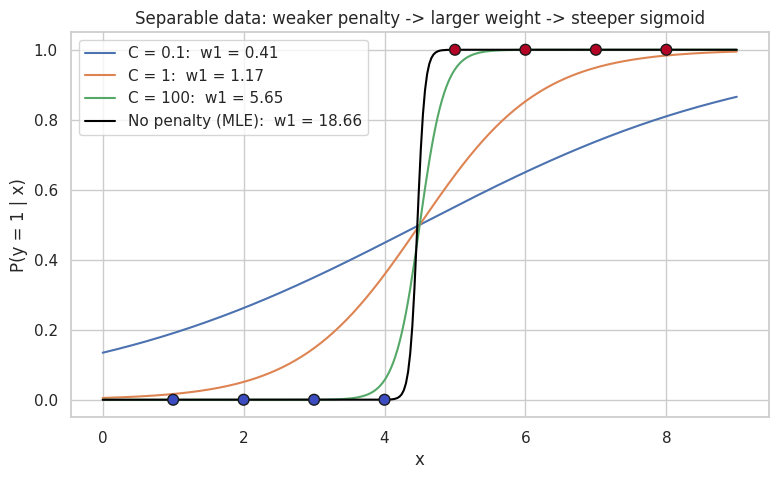

In [ ]:
x_sep = np.array([1, 2, 3, 4, 5, 6, 7, 8]).reshape(-1, 1)      # a perfectly separable 1-D dataset
y_sep = np.array([0, 0, 0, 0, 1, 1, 1, 1])
x_plot = np.linspace(0, 9, 300).reshape(-1, 1)

plt.figure(figsize=(9, 5))
plt.scatter(x_sep, y_sep, c=y_sep, cmap="coolwarm", edgecolor="k", s=60, zorder=3)

for C in [0.1, 1, 100]:
    model = LogisticRegression(C=C).fit(x_sep, y_sep)
    plt.plot(x_plot, model.predict_proba(x_plot)[:, 1], label=f"C = {C}:  w1 = {model.coef_[0, 0]:.2f}")

mle = LogisticRegression(penalty=None, max_iter=10000).fit(x_sep, y_sep)
plt.plot(x_plot, mle.predict_proba(x_plot)[:, 1], color="black", label=f"No penalty (MLE):  w1 = {mle.coef_[0, 0]:.2f}")

plt.xlabel("x")
plt.ylabel("P(y = 1 | x)")
plt.title("Separable data: weaker penalty -> larger weight -> steeper sigmoid")
plt.legend()
plt.show()

<div dir="rtl">

هرچه جریمه ضعیف‌تر، وزن بزرگ‌تر و سیگموید تیزتر. بدون جریمه سیگموید عملاً همان **تابع پلهٔ پرسپترون** شده است (اسلاید ۱۲): مدل حتی برای نقطه‌های کنار مرز ۱۰۰٪ مطمئن است! (در تئوری <span dir="ltr">$w_1 \to \infty$</span>؛ الگوریتم فقط چون گرادیان «به اندازهٔ کافی صفر» شد متوقف شد.) درمان: یک **پیش‌فرض** روی وزن‌ها، یعنی MAP.

</div>

<div dir="rtl">

## ۸. MLE در برابر MAP: منظم‌سازی L2 و L1

با یک پیش‌فرض روی وزن‌ها و بیشینه کردن احتمال پسین (MAP)، به cross-entropy **به‌علاوهٔ یک جریمه** می‌رسیم (اسلایدهای ۲۹ تا ۳۱):

</div>

$$\underbrace{J(\mathbf{w}) + \lambda \lVert \mathbf{w} \rVert_2^2}_{\text{Gaussian prior} \;\to\; \text{L2 (ridge)}} \qquad\qquad \underbrace{J(\mathbf{w}) + \lambda \lVert \mathbf{w} \rVert_1}_{\text{Laplace prior} \;\to\; \text{L1 (lasso)}} \qquad\qquad C = \frac{1}{\lambda}$$

<div dir="rtl">

در `scikit-learn`: `penalty="l2"` (پیش‌فرض)، `penalty="l1"` یا `penalty=None`؛ و **`C` کوچک = جریمهٔ قوی**. برای L1 باید `solver="liblinear"` یا `"saga"` بگذاریم، چون solver پیش‌فرض (`lbfgs`) فقط L2 و بدون جریمه را پشتیبانی می‌کند.

### ۸.۱ مدل کامل با همهٔ ۱۸ ویژگی

</div>

In [ ]:
def summary(model, X_tr, X_v):
    return {
        "train accuracy": model.score(X_tr, y_train),
        "val accuracy": model.score(X_v, y_val),
        "train log loss": log_loss(y_train, model.predict_proba(X_tr)[:, 1]),
        "val log loss": log_loss(y_val, model.predict_proba(X_v)[:, 1]),
        "length of w": np.linalg.norm(model.coef_),
    }


log_reg_full = LogisticRegression().fit(X_train_scaled, y_train)                           # L2, C = 1
log_reg_mle = LogisticRegression(penalty=None, max_iter=1000).fit(X_train_scaled, y_train)  # pure MLE

pd.DataFrame({
    "2 features (L2, C=1)": summary(log_reg_2, X_train_2, X_val_2),
    "18 features (L2, C=1)": summary(log_reg_full, X_train_scaled, X_val_scaled),
    "18 features (MLE)": summary(log_reg_mle, X_train_scaled, X_val_scaled),
}).T.round(3)

,train accuracy,val accuracy,train log loss,val log loss,length of w
"2 features (L2, C=1)",0.725,0.750,0.551,0.540,1.177
"18 features (L2, C=1)",0.796,0.793,0.425,0.447,1.257
18 features (MLE),0.796,0.793,0.425,0.447,1.272


<div dir="rtl">

- با همهٔ ویژگی‌ها دقت validation از حدود ۷۵٪ به حدود **۷۹٪** رسید و log loss هم کم شد. ✅
- با جریمه و بدون جریمه **تقریباً یکسان**: ۵۵۰ بیمار و فقط ۱۸ وزن داریم و داده جدایی‌پذیر نیست. جریمه وقتی مهم می‌شود که ویژگی‌ها نسبت به نمونه‌ها زیاد باشند (بخش ۸.۲).

وزن‌ها را ببینیم؛ چون همه‌چیز استاندارد است، اندازه‌شان قابل مقایسه است:

</div>

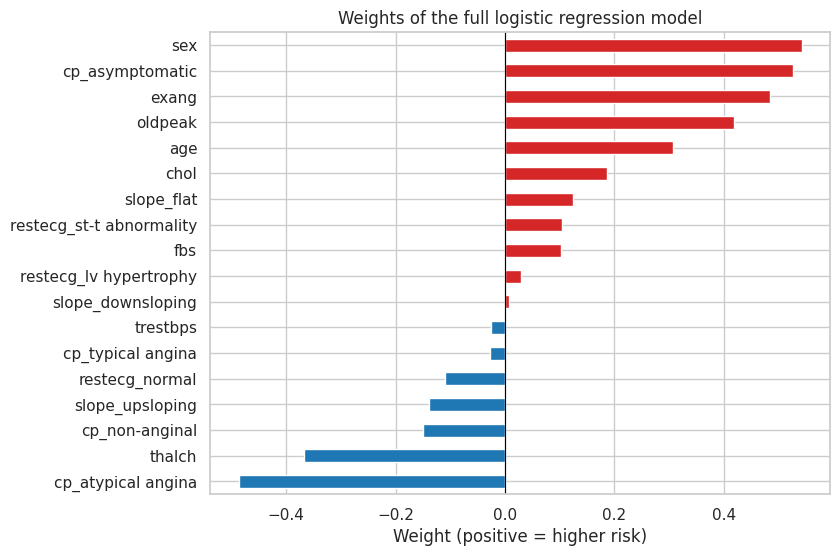

In [ ]:
weights = pd.Series(log_reg_full.coef_[0], index=X_train_scaled.columns).sort_values()

weights.plot.barh(figsize=(8, 6), color=np.where(weights > 0, "tab:red", "tab:blue"))
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Weight (positive = higher risk)")
plt.title("Weights of the full logistic regression model")
plt.show()

<div dir="rtl">

بیشترین افزایش خطر: مرد بودن، درد «بدون علامت» (`cp_asymptomatic`)، درد هنگام ورزش (`exang`) و افت ST. بیشترین کاهش خطر: درد «آتیپیک» و ضربان بالا در تست ورزش. (این‌ها **همبستگی**‌اند، نه لزوماً علت.)

### ۸.۲ انتخاب `C` با validation

`C` یک **ابرپارامتر** است و باید با validation انتخاب شود. برای این‌که اثر MAP واضح دیده شود، دو حالت را مقایسه می‌کنیم:

۱. همین ۱۸ ویژگی.

۲. همهٔ جمله‌های درجهٔ ۲ آن‌ها با `PolynomialFeatures`: **۱۸۹ ویژگی** برای فقط ۵۵۰ بیمار!

برای مقدارهای مختلف `C` هر دو مدل را آموزش می‌دهیم و log loss را روی train و validation ثبت می‌کنیم (چند ثانیه طول می‌کشد):

</div>

In [ ]:
poly = make_pipeline(PolynomialFeatures(degree=2, include_bias=False), StandardScaler())
X_train_poly = poly.fit_transform(X_train_scaled)
X_val_poly = poly.transform(X_val_scaled)
print("Degree-2 features:", X_train_poly.shape)

C_values = np.logspace(-3, 3, 25)       # from 0.001 to 1000
rows = []
for C in C_values:
    model = LogisticRegression(C=C, max_iter=5000).fit(X_train_scaled, y_train)
    poly_model = LogisticRegression(C=C, max_iter=5000).fit(X_train_poly, y_train)
    rows.append({
        "C": C,
        "train (18 features)": log_loss(y_train, model.predict_proba(X_train_scaled)[:, 1]),
        "validation (18 features)": log_loss(y_val, model.predict_proba(X_val_scaled)[:, 1]),
        "train (189 features)": log_loss(y_train, poly_model.predict_proba(X_train_poly)[:, 1]),
        "validation (189 features)": log_loss(y_val, poly_model.predict_proba(X_val_poly)[:, 1]),
    })

C_curve = pd.DataFrame(rows)

Degree-2 features: (550, 189)


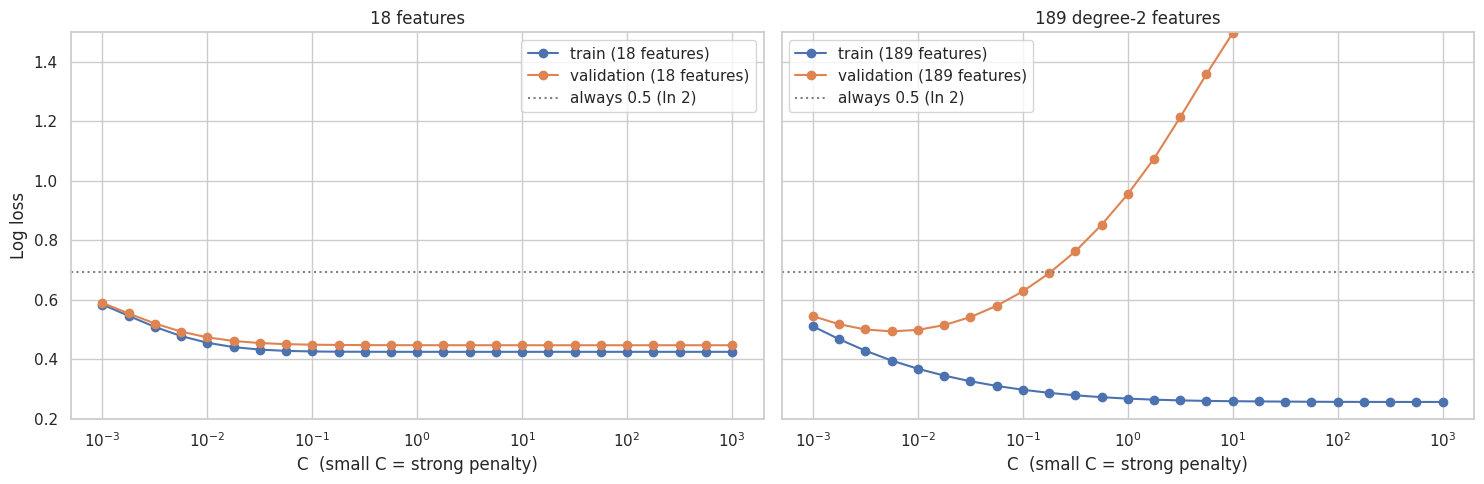

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

C_curve.plot(x="C", y=["train (18 features)", "validation (18 features)"], logx=True, marker="o", ax=axes[0])
axes[0].set_title("18 features")
C_curve.plot(x="C", y=["train (189 features)", "validation (189 features)"], logx=True, marker="o", ax=axes[1])
axes[1].set_title("189 degree-2 features")

for ax in axes:
    ax.axhline(np.log(2), color="gray", linestyle=":", label="always 0.5 (ln 2)")
    ax.set_xlabel("C  (small C = strong penalty)")
    ax.set_ylabel("Log loss")
    ax.set_ylim(0.2, 1.5)
    ax.legend()

plt.tight_layout()
plt.show()

<div dir="rtl">

دو داستان کاملاً متفاوت:

- **چپ (۱۸ ویژگی):** با `C` خیلی کوچک همهٔ وزن‌ها به صفر می‌چسبند و log loss به <span dir="ltr">$\ln 2$</span> نزدیک می‌شود (**underfitting**). از حدود `C = 0.1` به بعد منحنی **صاف** است.
- **راست (۱۸۹ ویژگی):** با `C` بزرگ (نزدیک MLE) هزینهٔ train مدام کم می‌شود ولی هزینهٔ validation **منفجر** می‌شود (**overfitting**). این‌جا MAP نجات‌دهنده است و فقط با `C` کوچک مدل قابل‌استفاده می‌ماند. حتی بهترین حالتش هم از مدل سادهٔ ۱۸ ویژگی بدتر است: **مدل انعطاف‌پذیرتر همیشه بهتر نیست.**

درس اسلاید ۴۰: «هدف، هزینهٔ کمتر روی train نیست.»

**انتخاب `C`:** چون منحنی چپ صاف است و بیش از ده مقدار `C` عملاً یک نتیجه می‌دهند، کورکورانه کمترین عدد را برنمی‌داریم. قاعدهٔ رایج: از بین `C`هایی که هزینهٔ validation آن‌ها حداکثر **۰٫۰۰۵** از بهترین بیشتر است، **کوچک‌ترین** را انتخاب کن؛ یعنی وقتی نتیجه‌ها برابرند، مدل با جریمهٔ قوی‌تر (ساده‌تر و پایدارتر).

</div>

In [ ]:
best_val_loss = C_curve["validation (18 features)"].min()
almost_best = C_curve[C_curve["validation (18 features)"] <= best_val_loss + 0.005]
best_C = almost_best["C"].min()

print("Lowest validation log loss:", round(best_val_loss, 3))
print("Chosen C:", round(best_C, 3), " -> validation log loss:", round(almost_best["validation (18 features)"].iloc[0], 3))

Lowest validation log loss: 0.447
Chosen C: 0.056  -> validation log loss: 0.45


<div dir="rtl">

### ۸.۳ L2 در برابر L1: کوچک کردن یا صفر کردن؟

اسلاید ۳۳: L2 وزن‌ها را **کوچک** می‌کند ولی صفر نمی‌کند؛ L1 خیلی‌ها را **دقیقاً صفر** می‌کند (انتخاب ویژگی). برای هر `C` هر دو مدل را آموزش می‌دهیم و ۱۸ وزن را رسم می‌کنیم:

</div>

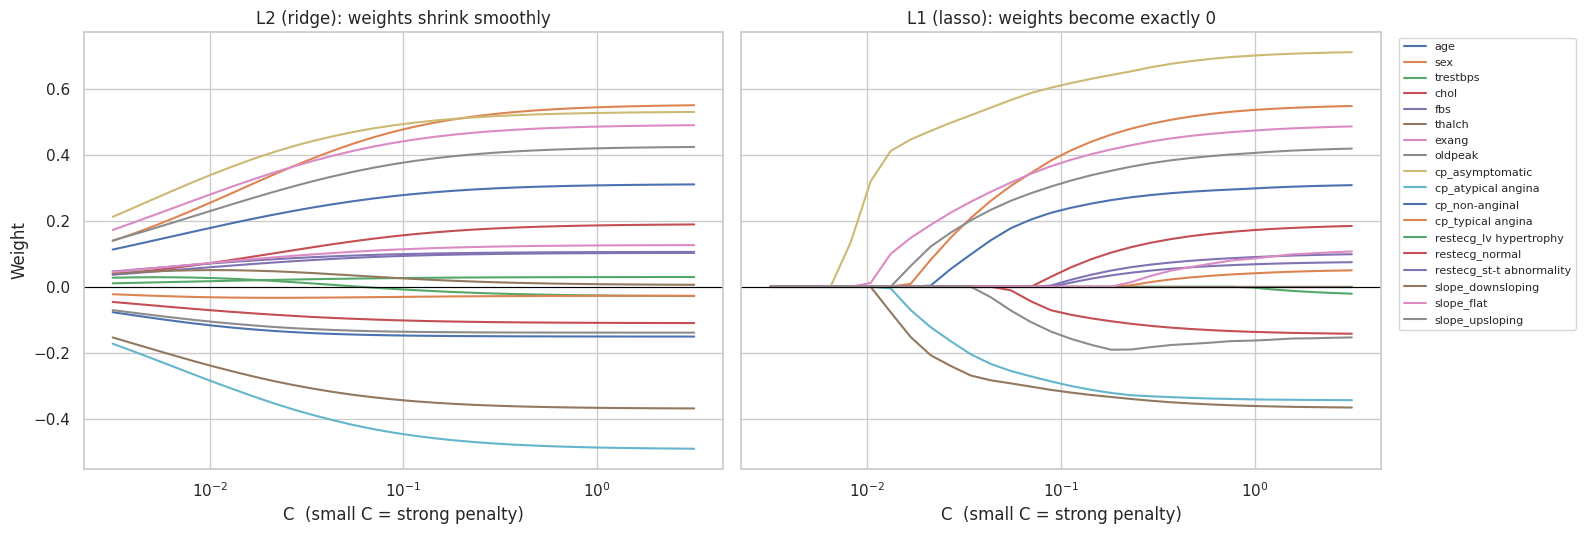

In [ ]:
C_path = np.logspace(-2.5, 0.5, 30)

weights_l2 = []
weights_l1 = []
for C in C_path:
    weights_l2.append(LogisticRegression(C=C).fit(X_train_scaled, y_train).coef_[0])
    weights_l1.append(LogisticRegression(C=C, penalty="l1", solver="liblinear").fit(X_train_scaled, y_train).coef_[0])

weights_l2 = pd.DataFrame(weights_l2, index=C_path, columns=X_train_scaled.columns)
weights_l1 = pd.DataFrame(weights_l1, index=C_path, columns=X_train_scaled.columns)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
weights_l2.plot(logx=True, legend=False, ax=axes[0])
axes[0].set_title("L2 (ridge): weights shrink smoothly")
weights_l1.plot(logx=True, ax=axes[1])
axes[1].set_title("L1 (lasso): weights become exactly 0")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
for ax in axes:
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xlabel("C  (small C = strong penalty)")
    ax.set_ylabel("Weight")
plt.tight_layout()
plt.show()

<div dir="rtl">

- **L2 (چپ):** با کم شدن `C` همهٔ وزن‌ها آرام به صفر نزدیک می‌شوند، ولی هیچ‌کدام صفر نمی‌شوند.
- **L1 (راست):** وزن‌ها یکی‌یکی **دقیقاً صفر** می‌شوند. با کم شدن جریمه، ویژگی‌ها یکی‌یکی «وارد» مدل می‌شوند و اولین‌ها مهم‌ترین‌اند.

یک مدل L1 با جریمهٔ نسبتاً قوی (`C = 0.03`) بسازیم:

</div>

In [ ]:
log_reg_l1 = LogisticRegression(C=0.03, penalty="l1", solver="liblinear")
log_reg_l1.fit(X_train_scaled, y_train)

l1_weights = pd.Series(log_reg_l1.coef_[0], index=X_train_scaled.columns)
print("Non-zero weights:", (l1_weights != 0).sum(), "out of", len(l1_weights))
print(l1_weights[l1_weights != 0].sort_values().round(3))
print()
print("Validation accuracy:", round(log_reg_l1.score(X_val_scaled, y_val), 3),
      " validation log loss:", round(log_loss(y_val, log_reg_l1.predict_proba(X_val_scaled)[:, 1]), 3))

Non-zero weights: 7 out of 18
thalch               -0.253
cp_atypical angina   -0.183
age                   0.074
sex                   0.176
oldpeak               0.181
exang                 0.240
cp_asymptomatic       0.507
dtype: float64

Validation accuracy: 0.766  validation log loss: 0.498


<div dir="rtl">

مدل L1 فقط با **۷ ویژگی از ۱۸** روی validation **کمی** ضعیف‌تر از مدل کامل است. برای پزشکی که می‌خواهد بداند «کدام آزمایش‌ها واقعاً مهم‌اند» این مدلی **ساده‌تر و تفسیرپذیرتر** است.

</div>

<div dir="rtl">

## ۹. گرادیان کاهشی در عمل

رگرسیون لجستیک جواب بسته ندارد، ولی تابع هزینه‌اش **محدب** است و گرادیانش ساده (اسلایدهای ۳۵ تا ۳۷):

</div>

$$\nabla J(\mathbf{w}) = \sum_{i=1}^{n} \big(\sigma(\mathbf{w}^T\mathbf{x}^{(i)}) - y^{(i)}\big)\,\mathbf{x}^{(i)} \qquad\qquad \mathbf{w} \leftarrow \mathbf{w} - \eta\, \nabla J(\mathbf{w})$$

<div dir="rtl">

یعنی «(احتمال پیش‌بینی‌شده − برچسب) × ورودی»؛ هم‌شکل گرادیان رگرسیون خطی.

`LogisticRegression` به‌طور پیش‌فرض از روش شبه‌نیوتنی **L-BFGS** استفاده می‌کند. ولی `SGDClassifier(loss="log_loss")` همان مدل را با **گرادیان کاهشی تصادفی** آموزش می‌دهد: در هر قدم با گرادیان **یک نمونه**. با `partial_fit` آموزش را یک دور (epoch) جلو می‌بریم و بعد از هر دور هزینه را اندازه می‌گیریم:

</div>

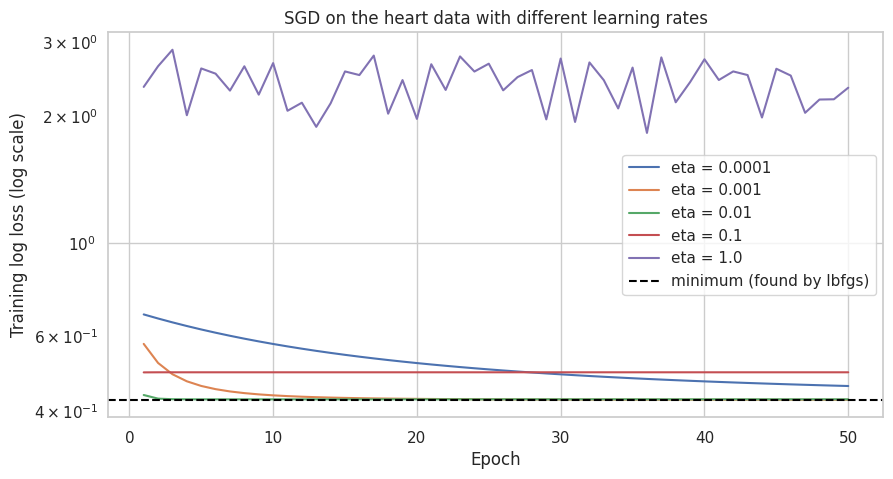

In [ ]:
from sklearn.linear_model import SGDClassifier

n_epochs = 50
best_possible_loss = log_loss(y_train, log_reg_mle.predict_proba(X_train_scaled)[:, 1])

plt.figure(figsize=(10, 5))
for eta in [0.0001, 0.001, 0.01, 0.1, 1.0]:
    sgd = SGDClassifier(loss="log_loss", penalty=None, learning_rate="constant", eta0=eta, random_state=0)
    losses = []
    for epoch in range(n_epochs):
        sgd.partial_fit(X_train_scaled, y_train, classes=[0, 1])        # one pass over the training data
        losses.append(log_loss(y_train, sgd.predict_proba(X_train_scaled)[:, 1]))
    plt.plot(range(1, n_epochs + 1), losses, label=f"eta = {eta}")

plt.axhline(best_possible_loss, color="black", linestyle="--", label="minimum (found by lbfgs)")
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Training log loss (log scale)")
plt.title("SGD on the heart data with different learning rates")
plt.legend()
plt.show()

<div dir="rtl">

- **<span dir="ltr">$\eta$</span> خیلی کوچک (۰٫۰۰۰۱):** درست ولی **خیلی کند**؛ بعد از ۵۰ دور هنوز نرسیده است.
- **<span dir="ltr">$\eta$</span> مناسب (۰٫۰۰۱ و ۰٫۰۱):** در چند دور به همان کمینهٔ lbfgs می‌رسد. تابع هزینه محدب است، پس کمینه یکی است.
- **<span dir="ltr">$\eta$</span> بزرگ (۰٫۱):** مدل دور کمینه **می‌چرخد** و در هزینهٔ بالاتری گیر می‌کند.
- **<span dir="ltr">$\eta$</span> خیلی بزرگ (۱):** پرش‌های نامنظم؛ هزینه حتی از مدل «همیشه ۰٫۵» هم بدتر است!

برای همین در عمل از یک solver آماده مثل `lbfgs` استفاده می‌کنیم (اسلاید ۴۰، توصیهٔ چهارم).

</div>

<div dir="rtl">

## ۱۰. مدل چقدر خوب است؟ معیارهای ارزیابی

**مدل اصلی** ما از این‌جا: لجستیک با ۱۸ ویژگی، L2 و `C` انتخاب‌شده در بخش ۸.۲.

### ۱۰.۱ ماتریس درهم‌ریختگی

<div dir="ltr">

| | مدل گفت: سالم (۰) | مدل گفت: بیمار (۱) |
|---|---|---|
| **واقعاً سالم** | **TN** | **FP**<br>هشدار اشتباه |
| **واقعاً بیمار** | **FN**<br>⚠️ بیمار را ندیدیم | **TP** |

</div>

</div>

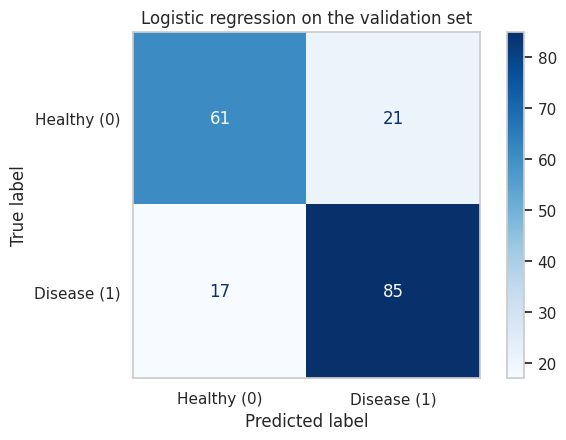

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

final_model = LogisticRegression(C=best_C)
final_model.fit(X_train_scaled, y_train)

p_val = final_model.predict_proba(X_val_scaled)[:, 1]      # P(disease) for every validation patient
y_val_pred = final_model.predict(X_val_scaled)             # the same as (p_val >= 0.5)

ConfusionMatrixDisplay.from_predictions(y_val, y_val_pred, display_labels=["Healthy (0)", "Disease (1)"], cmap="Blues")
plt.title("Logistic regression on the validation set")
plt.grid(False)
plt.show()

<div dir="rtl">

### ۱۰.۲ Accuracy، Precision، Recall و F1

</div>

$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN} \qquad \text{Precision} = \frac{TP}{TP + FP} \qquad \text{Recall} = \frac{TP}{TP + FN} \qquad F_1 = \frac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$

<div dir="rtl">

**Precision:** از کسانی که گفتیم «بیمار»، چند درصد واقعاً بیمار بودند؟ **Recall:** از همهٔ بیماران، چند درصد را پیدا کردیم؟ `classification_report` همه را برای هر دو کلاس می‌دهد. خط پایه هم مدل تنبل **«همه بیمارند»** است (کلاس اکثریت):

</div>

In [ ]:
from sklearn.metrics import classification_report

print("Logistic regression:")
print(classification_report(y_val, y_val_pred, target_names=["Healthy", "Disease"]))

y_always_sick = np.ones(len(y_val), dtype=int)
print("Always sick:")
print(classification_report(y_val, y_always_sick, target_names=["Healthy", "Disease"], zero_division=0))

Logistic regression:
              precision    recall  f1-score   support

     Healthy       0.78      0.74      0.76        82
     Disease       0.80      0.83      0.82       102

    accuracy                           0.79       184
   macro avg       0.79      0.79      0.79       184
weighted avg       0.79      0.79      0.79       184

Always sick:
              precision    recall  f1-score   support

     Healthy       0.00      0.00      0.00        82
     Disease       0.55      1.00      0.71       102

    accuracy                           0.55       184
   macro avg       0.28      0.50      0.36       184
weighted avg       0.31      0.55      0.40       184



<div dir="rtl">

مدل تنبل **recall کامل** برای بیماران دارد؛ هیچ بیماری را از دست نمی‌دهد! ولی precision آن فقط ۰٫۵۵ است و همه را به آنژیوگرافی می‌فرستد. همان‌طور که accuracy تنها گمراه‌کننده بود، **recall تنها هم گمراه‌کننده است**.

### ۱۰.۳ منحنی ROC و AUC

برای ROC یک **امتیاز پیوسته** لازم است؛ در لجستیک خیلی طبیعی است: **خود احتمال**. **AUC** یعنی: اگر یک بیمار و یک فرد سالم تصادفی انتخاب کنیم، با چه احتمالی مدل به بیمار امتیاز بالاتری می‌دهد؟ مدل‌ها را با یک **پرسپترون** روی همین ۱۸ ویژگی مقایسه می‌کنیم (برای آن از `decision_function` استفاده می‌کنیم، چون `predict_proba` ندارد):

</div>

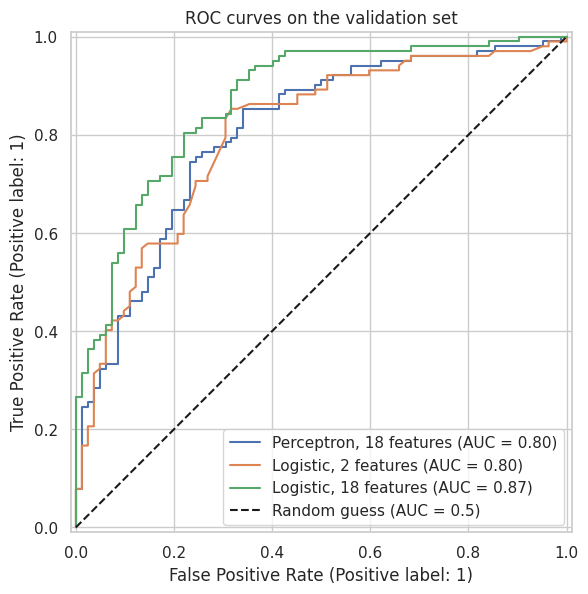

In [ ]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay

perceptron_full = Perceptron(random_state=0)
perceptron_full.fit(X_train_scaled, y_train)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
RocCurveDisplay.from_predictions(y_val, perceptron_full.decision_function(X_val_scaled), name="Perceptron, 18 features", ax=ax)
RocCurveDisplay.from_predictions(y_val, p_val_2, name="Logistic, 2 features", ax=ax)
RocCurveDisplay.from_predictions(y_val, p_val, name="Logistic, 18 features", ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.5)")
ax.set_title("ROC curves on the validation set")
ax.legend()
plt.show()

<div dir="rtl">

یک تابع کوچک (مثل نوت‌بوک قبلی) همهٔ معیارها را جمع می‌کند:

</div>

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


def evaluate(y_true, y_pred, scores):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, scores),
    }


pd.DataFrame({
    "Always sick": evaluate(y_val, y_always_sick, np.full(len(y_val), 0.5)),
    "Perceptron (18 features)": evaluate(y_val, perceptron_full.predict(X_val_scaled), perceptron_full.decision_function(X_val_scaled)),
    "Logistic (2 features)": evaluate(y_val, log_reg_2.predict(X_val_2), p_val_2),
    "Logistic L1 (C=0.03)": evaluate(y_val, log_reg_l1.predict(X_val_scaled), log_reg_l1.predict_proba(X_val_scaled)[:, 1]),
    "Logistic L2 (best C)": evaluate(y_val, y_val_pred, p_val),
}).T.round(3)

,accuracy,precision,recall,F1,ROC-AUC
Always sick,0.554,0.554,1.000,0.713,0.500
Perceptron (18 features),0.739,0.750,0.794,0.771,0.805
Logistic (2 features),0.750,0.764,0.794,0.779,0.803
Logistic L1 (C=0.03),0.766,0.798,0.775,0.786,0.861
Logistic L2 (best C),0.793,0.802,0.833,0.817,0.868


<div dir="rtl">

- لجستیک با ۱۸ ویژگی تقریباً در همهٔ معیارها بهترین است.
- پرسپترون با **همان ۱۸ ویژگی** و همان نوع مرز خطی، ROC-AUC کمتری دارد. تفاوت در **تابع هزینه** است: پرسپترون فقط می‌خواهد نقطه‌ها طرف درست باشند، ولی cross-entropy از مدل **احتمال درست** می‌خواهد؛ نتیجه، رتبه‌بندی بهتر بیماران است.

### ۱۰.۴ جابه‌جا کردن آستانهٔ تصمیم

`predict` همیشه آستانهٔ ۰٫۵ را به کار می‌برد. ولی با احتمال، آستانه معنای روشنی دارد: «هر کس احتمال بیماری‌اش بیشتر از <span dir="ltr">$t$</span> بود، به آنژیوگرافی برود.» در غربالگری، ندیدن یک بیمار (FN) خیلی گران‌تر از یک آزمایش اضافه (FP) است. معیارها را برای آستانه‌های مختلف روی **validation** حساب می‌کنیم:

</div>

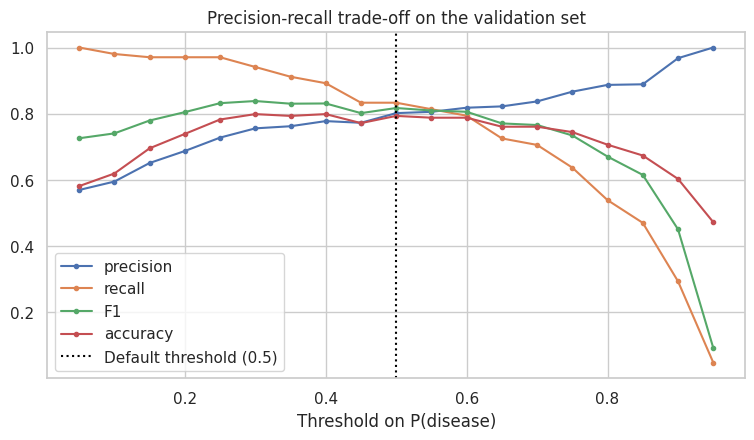

In [ ]:
thresholds = np.round(np.arange(0.05, 0.96, 0.05), 2)

rows = []
for t in thresholds:
    y_pred_t = (p_val >= t).astype(int)
    rows.append({"threshold": t,
                 "precision": precision_score(y_val, y_pred_t, zero_division=0),
                 "recall": recall_score(y_val, y_pred_t),
                 "F1": f1_score(y_val, y_pred_t),
                 "accuracy": accuracy_score(y_val, y_pred_t)})

threshold_table = pd.DataFrame(rows)

threshold_table.plot(x="threshold", y=["precision", "recall", "F1", "accuracy"], figsize=(9, 4.5), marker=".")
plt.axvline(0.5, color="black", linestyle=":", label="Default threshold (0.5)")
plt.xlabel("Threshold on P(disease)")
plt.title("Precision-recall trade-off on the validation set")
plt.legend()
plt.show()

<div dir="rtl">

فرض کنید پزشکان گفته‌اند: «دست‌کم **۹۰٪** بیماران باید پیدا شوند.» از بین آستانه‌هایی که این شرط را دارند، **بزرگ‌ترین** را برمی‌داریم تا هشدار اشتباه کم بماند:

</div>

In [ ]:
good_recall = threshold_table[threshold_table["recall"] >= 0.90]
best_threshold = good_recall["threshold"].max()

print("Chosen threshold:", best_threshold)
threshold_table[threshold_table["threshold"].isin([best_threshold, 0.5])].round(3)

Chosen threshold: 0.35


,threshold,precision,recall,F1,accuracy
6,0.35,0.762,0.912,0.830,0.793
9,0.50,0.802,0.833,0.817,0.793


<div dir="rtl">

با این آستانه recall به بالای ۹۰٪ رسید و قیمتش precision کمی کمتر بود. آن را در بخش ۱۳ روی test امتحان می‌کنیم.

</div>

<div dir="rtl">

## ۱۱. همه‌چیز در یک Pipeline و تنظیم با GridSearchCV

تا این‌جا پیش‌پردازش را قدم‌به‌قدم انجام دادیم تا همه‌چیز را ببینیم. در یک پروژهٔ واقعی همهٔ قدم‌ها را در یک **Pipeline** می‌گذاریم (مثل نوت‌بوک رگرسیون خطی):
- کد کوتاه‌تر است و قدمی جا نمی‌افتد.
- در cross-validation هر fold پیش‌پردازش را **فقط روی train همان fold** فیت می‌کند؛ پس اطلاعات به بیرون نشت نمی‌کند.

`ColumnTransformer` برای ستون‌های عددی و متنی پیش‌پردازش متفاوت می‌گذارد؛ دقیقاً همان کار بخش ۴:

</div>

In [ ]:
from sklearn.compose import ColumnTransformer

preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_cols),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                          OneHotEncoder(handle_unknown="ignore", sparse_output=False)), categorical_cols),
])

pipe = make_pipeline(preprocess, StandardScaler(), LogisticRegression(solver="liblinear"))
pipe

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('num',
                                                  SimpleImputer(strategy='median'),
                                                  ['age', 'sex', 'trestbps',
                                                   'chol', 'fbs', 'thalch',
                                                   'exang', 'oldpeak']),
                                                 ('cat',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['cp', 'restecg',
                                                   'slope'])])),
                ('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(solver='liblinear'))])

<div dir="rtl">

حالا با `GridSearchCV` همزمان **نوع جریمه** (L1 یا L2) و **`C`** را با cross-validation پنج‌تایی و معیار ROC-AUC انتخاب می‌کنیم. چون Pipeline خودش پیش‌پردازش می‌کند، دادهٔ **خام** train و validation را با هم (`X_temp`) به آن می‌دهیم؛ test دست‌نخورده می‌ماند.

💡 اسم پارامترها در Pipeline به شکل `<اسم قدم>__<اسم پارامتر>` است و `make_pipeline` اسم هر قدم را از اسم کلاسش با حروف کوچک می‌سازد.

</div>

In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    "logisticregression__penalty": ["l1", "l2"],
    "logisticregression__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
}

grid = GridSearchCV(pipe, param_grid, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42), scoring="roc_auc")
grid.fit(X_temp, y_temp)

print("Best parameters:", grid.best_params_)
print("Best mean CV ROC-AUC:", round(grid.best_score_, 3))

cv_results = pd.DataFrame(grid.cv_results_)
cv_results = cv_results[["param_logisticregression__penalty", "param_logisticregression__C", "mean_test_score", "std_test_score"]]
cv_results.sort_values("mean_test_score", ascending=False).head(5).round(3)

Best parameters: {'logisticregression__C': 0.01, 'logisticregression__penalty': 'l2'}
Best mean CV ROC-AUC: 0.869


,param_logisticregression__penalty,param_logisticregression__C,mean_test_score,std_test_score
1,l2,0.01,0.869,0.046
4,l1,0.10,0.869,0.045
3,l2,0.03,0.868,0.046
6,l1,0.30,0.867,0.046
5,l2,0.10,0.866,0.046


<div dir="rtl">

تفاوت بهترین ترکیب‌ها خیلی کمتر از انحراف معیار (`std`) بین foldهاست؛ چندین ترکیب عملاً هم‌سطح‌اند. همان چیزی که منحنی بخش ۸.۲ نشان داد. `GridSearchCV` در پایان مدل را با بهترین پارامترها روی کل `X_temp` دوباره آموزش می‌دهد؛ این مدل آماده است که در بخش ۱۳ مستقیماً روی دادهٔ خام test امتحان شود.

</div>

<div dir="rtl">

## ۱۲. رگرسیون لجستیک چندکلاسه (Softmax): دوباره پنگوئن‌ها 🐧

در نوت‌بوک قبلی پرسپترون چندکلاسه را روی پنگوئن‌ها امتحان کردیم. حالا همان مسئله را با **Softmax** حل می‌کنیم. برای هر کلاس یک بردار وزن <span dir="ltr">$\mathbf{w}_k$</span> و امتیاز <span dir="ltr">$z_k = \mathbf{w}_k^T\mathbf{x}$</span> داریم، و softmax امتیازها را به <span dir="ltr">$K$</span> احتمال تبدیل می‌کند که جمعشان ۱ است (اسلایدهای ۴۲ تا ۴۸):

</div>

$$P(y = k \mid \mathbf{x}) = \frac{e^{\mathbf{w}_k^T\mathbf{x}}}{\sum_{j=1}^{K} e^{\mathbf{w}_j^T\mathbf{x}}} \qquad\qquad \hat{y} = \arg\max_k\, P(y = k \mid \mathbf{x}) \qquad\qquad J(W) = -\frac{1}{n}\sum_{i=1}^{n}\sum_{k=1}^{K} y_k^{(i)} \log P(y = k \mid \mathbf{x}^{(i)})$$

<div dir="rtl">

💡 کلاس جدیدی لازم نیست! وقتی برچسب‌ها بیش از دو مقدار دارند، `LogisticRegression` با solver پیش‌فرض **خودش** softmax (multinomial) را آموزش می‌دهد.

مثل نوت‌بوک قبلی، دو ویژگی **طول** و **عمق نوک** و همان تقسیم ۷۰٪/۳۰٪ را به کار می‌بریم تا نتیجه‌ها قابل مقایسه باشند:

</div>

In [ ]:
penguins = pd.read_csv("/content/penguins.csv")

penguin_features = ["bill_length_mm", "bill_depth_mm"]
species_names = ["Adelie", "Chinstrap", "Gentoo"]

Xp = penguins[penguin_features]
yp = penguins["species"].map({"Adelie": 0, "Chinstrap": 1, "Gentoo": 2}).to_numpy()

Xp_train, Xp_test, yp_train, yp_test = train_test_split(Xp, yp, test_size=0.3, random_state=42, stratify=yp)

print(penguins["species"].value_counts())
print("Missing values in train:", Xp_train.isna().sum().sum())

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64
Missing values in train: 2


In [ ]:
softmax_model = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression())
softmax_model.fit(Xp_train, yp_train)

# one weight vector (row) per class
softmax_weights = pd.DataFrame(softmax_model[-1].coef_, index=species_names, columns=penguin_features)
softmax_weights["intercept"] = softmax_model[-1].intercept_
softmax_weights.round(2)

,bill_length_mm,bill_depth_mm,intercept
Adelie,-2.72,2.10,0.20
Chinstrap,0.98,0.97,0.41
Gentoo,1.75,-3.07,-0.61


<div dir="rtl">

ماتریس وزن‌ها **سه سطر** دارد؛ یکی برای هر گونه (اسلاید ۴۳). Gentoo برای طول نوک وزن مثبت و برای عمق وزن خیلی منفی دارد (نوک **بلند و باریک**) و Adelie برعکس.

احتمال‌های چند پنگوئن test و حساب **دستی** softmax از روی امتیازهای `decision_function`:

</div>

In [ ]:
proba_penguins = pd.DataFrame(softmax_model.predict_proba(Xp_test), columns=species_names)
proba_penguins["sum"] = proba_penguins.sum(axis=1)
proba_penguins["truth"] = [species_names[k] for k in yp_test]
print(proba_penguins.head().round(3))

z_penguins = softmax_model.decision_function(Xp_test)          # shape: (n_samples, 3)
p_by_hand = np.exp(z_penguins) / np.exp(z_penguins).sum(axis=1, keepdims=True)
print()
print("Softmax by hand == predict_proba for all test penguins?", np.allclose(p_by_hand, softmax_model.predict_proba(Xp_test)))

   Adelie  Chinstrap  Gentoo  sum      truth
0   0.000      0.016   0.984  1.0     Gentoo
1   0.164      0.672   0.164  1.0  Chinstrap
2   0.981      0.019   0.001  1.0     Adelie
3   0.992      0.008   0.000  1.0     Adelie
4   0.013      0.942   0.045  1.0  Chinstrap

Softmax by hand == predict_proba for all test penguins? True


<div dir="rtl">

جمع احتمال‌های هر ردیف ۱ است و حساب دستی با کتابخانه یکی است. ✅ برای بیشتر پنگوئن‌ها مدل کاملاً مطمئن است، ولی برای بعضی (مثل پنگوئن دوم) احتمال بین گونه‌ها تقسیم شده است.

### نواحی تصمیم: Softmax در برابر One-vs-Rest

راه قدیمی‌تر **One-vs-Rest (OvR)** است: برای هر کلاس یک لجستیک **جداگانه** («Adelie یا غیر Adelie؟»، ...) و در آخر کلاسی با بیشترین احتمال. در softmax سه بردار وزن **با هم** و با یک تابع هزینه یاد گرفته می‌شوند. نواحی و خطوط «بیشترین احتمال = ۰٫۶ و ۰٫۹» را رسم می‌کنیم (مثل اسلاید ۵۰):

</div>

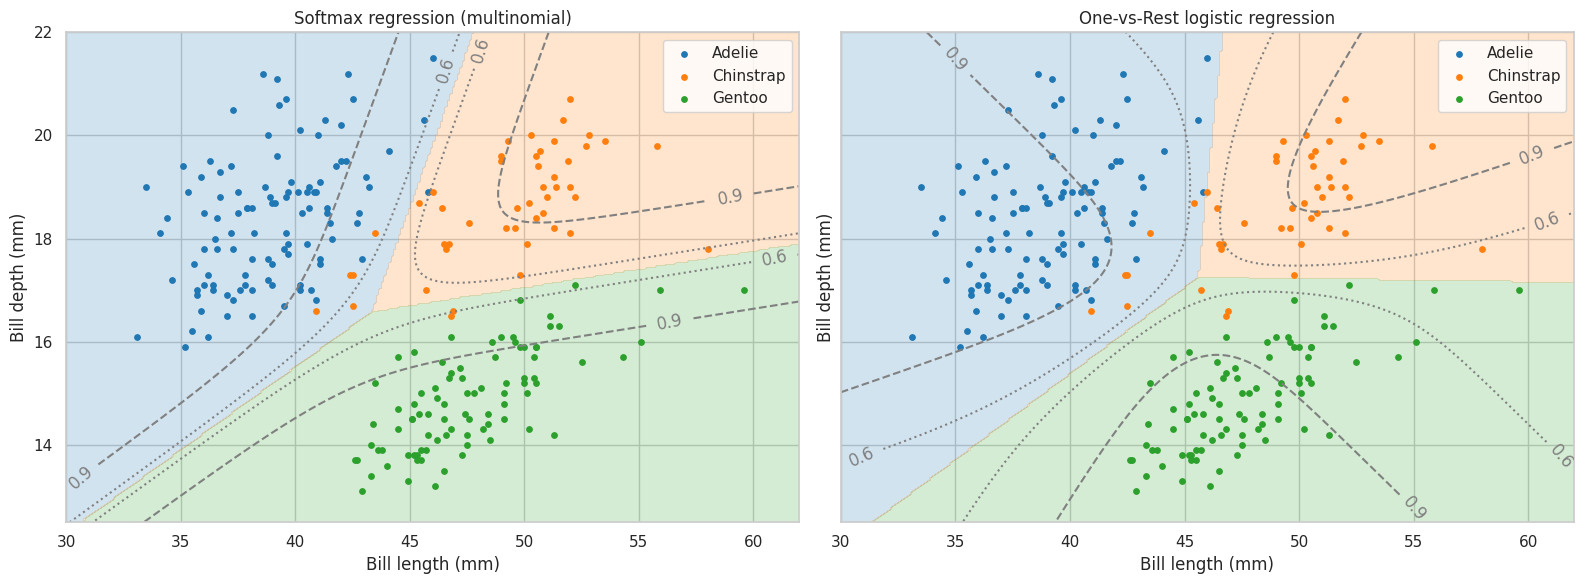

In [ ]:
from sklearn.multiclass import OneVsRestClassifier

ovr_model = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), OneVsRestClassifier(LogisticRegression()))
ovr_model.fit(Xp_train, yp_train)

colors = ["tab:blue", "tab:orange", "tab:green"]


def plot_regions(model, ax, title):
    length_grid, depth_grid = np.meshgrid(np.linspace(30, 62, 300), np.linspace(12.5, 22, 300))
    grid = pd.DataFrame({"bill_length_mm": length_grid.ravel(), "bill_depth_mm": depth_grid.ravel()})

    proba = model.predict_proba(grid)
    region = proba.argmax(axis=1).reshape(length_grid.shape)      # the most probable class
    max_proba = proba.max(axis=1).reshape(length_grid.shape)      # how sure the model is

    ax.contourf(length_grid, depth_grid, region, levels=[-0.5, 0.5, 1.5, 2.5], colors=colors, alpha=0.2)
    lines = ax.contour(length_grid, depth_grid, max_proba, levels=[0.6, 0.9], colors="gray", linestyles=["dotted", "dashed"])
    ax.clabel(lines, fmt="%.1f")
    for k in range(3):
        ax.scatter(Xp_train[yp_train == k]["bill_length_mm"], Xp_train[yp_train == k]["bill_depth_mm"],
                   s=15, color=colors[k], label=species_names[k])
    ax.set_xlabel("Bill length (mm)")
    ax.set_ylabel("Bill depth (mm)")
    ax.set_title(title)
    ax.legend()


fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
plot_regions(softmax_model, axes[0], "Softmax regression (multinomial)")
plot_regions(ovr_model, axes[1], "One-vs-Rest logistic regression")
plt.tight_layout()
plt.show()

<div dir="rtl">

- در هر دو مدل نواحی **محدب**‌اند و مرز هر دو کلاس یک خط راست است؛ هر دو مدل خطی‌اند.
- نواحی شبیه‌اند، ولی **خطوط اطمینان** خیلی فرق دارند: در OvR نواحی مطمئن (بالای ۰٫۹) کوچک‌تر و عجیب‌ترند. دلیلش این است که مدل «Chinstrap یا بقیه؟» کار سختی دارد: Chinstrap بین دو گونهٔ دیگر گیر افتاده و یک خط نمی‌تواند آن را از **هر دو** طرف جدا کند. softmax سه بردار وزن را **با هم** یاد می‌گیرد و احتمال‌هایش منسجم‌ترند.

### ارزیابی روی test

برای چند کلاس، `classification_report` معیارها را برای **هر کلاس** و دو میانگین **macro** (سادهٔ کلاس‌ها) و **weighted** (وزن‌دار با تعداد نمونه‌ها) می‌دهد:

</div>

              precision    recall  f1-score   support

      Adelie       0.96      1.00      0.98        46
   Chinstrap       0.84      0.76      0.80        21
      Gentoo       0.92      0.92      0.92        37

    accuracy                           0.92       104
   macro avg       0.91      0.89      0.90       104
weighted avg       0.92      0.92      0.92       104



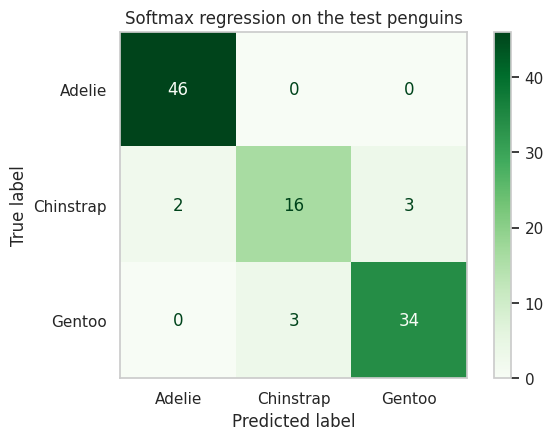

In [ ]:
yp_pred = softmax_model.predict(Xp_test)

print(classification_report(yp_test, yp_pred, target_names=species_names))

ConfusionMatrixDisplay.from_predictions(yp_test, yp_pred, display_labels=species_names, cmap="Greens")
plt.title("Softmax regression on the test penguins")
plt.grid(False)
plt.show()

<div dir="rtl">

مقایسهٔ softmax، OvR و پرسپترون چندکلاسه. ROC-AUC چندکلاسه را با `multi_class="ovr"` حساب می‌کنیم (میانگین AUCهای «هر کلاس در برابر بقیه»). این معیار، مثل log loss، **احتمال** لازم دارد؛ پس برای پرسپترون قابل محاسبه نیست:

</div>

In [ ]:
perceptron_penguins = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Perceptron(random_state=0))
perceptron_penguins.fit(Xp_train, yp_train)

penguin_results = {}
for name, model in [("Softmax", softmax_model), ("One-vs-Rest", ovr_model)]:
    proba = model.predict_proba(Xp_test)
    penguin_results[name] = {
        "accuracy": accuracy_score(yp_test, model.predict(Xp_test)),
        "macro F1": f1_score(yp_test, model.predict(Xp_test), average="macro"),
        "log loss": log_loss(yp_test, proba),
        "ROC-AUC (ovr)": roc_auc_score(yp_test, proba, multi_class="ovr"),
    }

penguin_results["Perceptron"] = {
    "accuracy": accuracy_score(yp_test, perceptron_penguins.predict(Xp_test)),
    "macro F1": f1_score(yp_test, perceptron_penguins.predict(Xp_test), average="macro"),
    "log loss": np.nan,
    "ROC-AUC (ovr)": np.nan,
}

pd.DataFrame(penguin_results).T.round(3)

,accuracy,macro F1,log loss,ROC-AUC (ovr)
Softmax,0.923,0.899,0.189,0.992
One-vs-Rest,0.894,0.862,0.276,0.982
Perceptron,0.913,0.884,NaN,NaN


<div dir="rtl">

softmax در همهٔ معیارها بهترین است؛ به‌خصوص log loss آن خیلی کمتر از OvR است: احتمال‌هایش **قابل اعتمادترند**.

</div>

<div dir="rtl">

## ۱۳. لحظهٔ حقیقت: ارزیابی نهایی روی Test 🏁

به بیماران قلبی برمی‌گردیم. انتخاب‌ها (تعداد ویژگی‌ها، `C`، نوع جریمه و آستانه) با validation یا cross-validation انجام شده است؛ فقط `C = 0.03` مدل L1 را خودمان آگاهانه برای یک مدل ساده‌تر انتخاب کردیم. حالا **فقط یک بار** روی test ارزیابی می‌کنیم:

</div>

In [ ]:
p_test = final_model.predict_proba(X_test_scaled)[:, 1]

final_results = {
    "Always sick (baseline)": evaluate(y_test, np.ones(len(y_test), dtype=int), np.full(len(y_test), 0.5)),
    "Perceptron (18 features)": evaluate(y_test, perceptron_full.predict(X_test_scaled), perceptron_full.decision_function(X_test_scaled)),
    "Logistic L1 (C=0.03)": evaluate(y_test, log_reg_l1.predict(X_test_scaled), log_reg_l1.predict_proba(X_test_scaled)[:, 1]),
    "Logistic L2 (best C)": evaluate(y_test, final_model.predict(X_test_scaled), p_test),
    "GridSearchCV pipeline": evaluate(y_test, grid.predict(X_test), grid.predict_proba(X_test)[:, 1]),   # raw test data
    f"Logistic L2, threshold {best_threshold}": evaluate(y_test, (p_test >= best_threshold).astype(int), p_test),
}

pd.DataFrame(final_results).T.round(3)

,accuracy,precision,recall,F1,ROC-AUC
Always sick (baseline),0.554,0.554,1.000,0.713,0.500
Perceptron (18 features),0.723,0.752,0.745,0.749,0.791
Logistic L1 (C=0.03),0.799,0.822,0.814,0.818,0.895
Logistic L2 (best C),0.793,0.791,0.853,0.821,0.892
GridSearchCV pipeline,0.799,0.804,0.843,0.823,0.890
"Logistic L2, threshold 0.35",0.815,0.774,0.941,0.850,0.892


<div dir="rtl">

- هر سه مدل لجستیک با ۱۸ ویژگی (L2، L1 و Pipeline) روی test به ROC-AUC حدود **۰٫۸۹** و دقت حدود **۸۰٪** رسیدند؛ حتی کمی بهتر از validation. یعنی انتخاب‌هایمان به دادهٔ تازه منتقل شد. این سه مدل **هم‌سطح‌اند** و مدل L1 فقط با **۷ ویژگی** پابه‌پای بقیه است.
- **پرسپترون** با همان ۱۸ ویژگی حدود ۱۰ امتیاز ROC-AUC عقب‌تر است (۰٫۷۹ در برابر ۰٫۸۹). هر دو مدل خطی‌اند؛ تفاوت در **تابع هزینه** است.
- **آستانهٔ انتخاب‌شده با validation** (۰٫۳۵) recall را از حدود ۸۵٪ به حدود **۹۴٪** رساند و precision فقط کمی پایین آمد. ROC-AUC تغییر نکرد، چون آستانه امتیازها را عوض نمی‌کند.

</div>

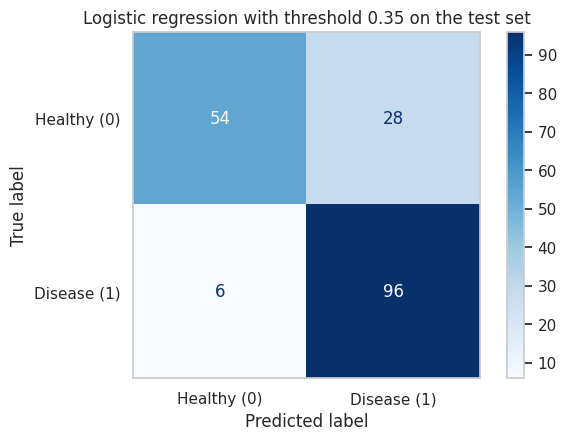

In [ ]:
y_test_final = (p_test >= best_threshold).astype(int)

ConfusionMatrixDisplay.from_predictions(y_test, y_test_final, display_labels=["Healthy (0)", "Disease (1)"], cmap="Blues")
plt.title(f"Logistic regression with threshold {best_threshold} on the test set")
plt.grid(False)
plt.show()

<div dir="rtl">

از **۱۰۲** بیمار test، مدل **۹۶ نفر** را پیدا کرد و فقط **۶ نفر** را ندید؛ قیمتش **۲۸** هشدار اشتباه از ۸۲ فرد سالم بود. برای یک **غربالگری** که بعدش آنژیوگرافی می‌آید، معاملهٔ معقولی است. ولی این‌که چند هشدار اشتباه قابل قبول است تصمیمی **پزشکی** است، نه تصمیم مدل. کار رگرسیون لجستیک این است که برای هر بیمار یک **احتمال** بدهد و تصمیم را شفاف کند. 🫀

</div>

<div dir="rtl">

## ۱۴. جمع‌بندی

| مرحله | درسی که گرفتیم |
|---|---|
| داده | ستون‌هایی که ویژگی بیمار نیستند (اسم بیمارستان) گمراه‌کننده‌اند؛ صفرهای غیرممکن را پیدا کن |
| پیش‌پردازش | میانه برای عددی، پرتکرارترین برای متنی، one-hot برای دسته‌ای، scaling؛ و `fit` فقط روی train |
| سیگموید | خروجی بین ۰ و ۱ و مشتق‌پذیر؛ لجستیک یک «پرسپترون نرم» است |
| خروجی‌های مدل | `decision_function` = <span dir="ltr">$\mathbf{w}^T\mathbf{x}$</span>، `predict_proba` = <span dir="ltr">$\sigma(\mathbf{w}^T\mathbf{x})$</span>، `predict` = آستانهٔ ۰٫۵ |
| مرز تصمیم | <span dir="ltr">$\mathbf{w}^T\mathbf{x} = 0$</span> یک ابرصفحه است؛ با نگاشت ویژگی خمیده می‌شود |
| Cross-entropy | اشتباه با اطمینان را به‌شدت جریمه می‌کند؛ خط پایهٔ آن <span dir="ltr">$\ln 2$</span> است |
| دادهٔ جدایی‌پذیر | MLE وجود ندارد و وزن‌ها بی‌نهایت می‌شوند؛ MAP درمانش است |
| MAP | L2 وزن‌ها را کوچک و L1 صفرشان می‌کند؛ `C = 1/λ` را با validation انتخاب کن |
| گرادیان کاهشی | (احتمال − برچسب) × ورودی؛ نرخ یادگیری تعیین‌کننده است |
| معیارها | accuracy و recall هر کدام به‌تنهایی گمراه‌کننده‌اند؛ ROC-AUC با **احتمال** حساب می‌شود |
| آستانهٔ تصمیم | با احتمال معنای روشنی دارد؛ انتخابش با validation و با توجه به هزینهٔ خطاها |
| Pipeline | همهٔ قدم‌ها در یک شیء؛ بدون نشت اطلاعات در cross-validation |
| Softmax | یک بردار وزن برای هر کلاس و احتمال‌هایی با جمع ۱؛ معمولاً بهتر از One-vs-Rest |

### 🏋️ تمرین‌ها

۱. **اسم بیمارستان:** ستون `dataset` را با one-hot به مدل اضافه کنید. آیا validation بهتر می‌شود؟ حالا مدل را فقط روی سه بیمارستان آموزش دهید و روی بیماران **سوئیس** امتحان کنید. چه اتفاقی می‌افتد و چرا؟

۲. **خود گمشدن هم اطلاعات است:** به‌جای حذف `ca` و `thal`، نگهشان دارید و از `SimpleImputer(..., add_indicator=True)` استفاده کنید. مدل بهتر می‌شود؟

۳. **تفسیر وزن‌ها با odds ratio:** نشان دهید <span dir="ltr">$\log\frac{p}{1-p} = \mathbf{w}^T\mathbf{x}$</span>. سپس <span dir="ltr">$e^{w_j}$</span> را برای وزن‌های `log_reg_2` حساب کنید و تفسیر کنید: اگر `thalch` یک انحراف معیار (چند ضربه در دقیقه؟) زیاد شود، **شانس** بیماری در چه عددی ضرب می‌شود؟

۴. **گرادیان کاهشی دسته‌ای از صفر:** با `numpy` و فرمول اسلاید ۳۵ لجستیک را روی `X_train_scaled` آموزش دهید و وزن‌ها را با `LogisticRegression(penalty=None)` مقایسه کنید. همین کار را روی دادهٔ **استانداردنشده** (`X_train_enc`) هم انجام دهید؛ چه می‌بینید؟

۵. **Elastic Net:** با `LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0.5)` ترکیب L1 و L2 را امتحان کنید و `l1_ratio` و `C` را با `GridSearchCV` انتخاب کنید.

۶. **دمای softmax:** امتیازهای `decision_function` یک پنگوئن را بر «دما» <span dir="ltr">$T$</span> تقسیم کنید و softmax بگیرید (اسلاید ۴۵). برای <span dir="ltr">$T = 0.1, 1, 10$</span> احتمال‌ها چه تغییری می‌کنند؟

</div>